In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import root_numpy
import matplotlib

Welcome to JupyROOT 6.22/02


In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def getData(branchNames, dfNames, inputFiles, treeName):
    data = root_numpy.root2array(inputFiles, treeName, branches=branchNames)
    return pd.DataFrame(data, columns=dfNames)

In [4]:
def flatten(data, column):
    a = []
    for row in range(0,len(data)):
        a.append(data[row][column])
    return np.concatenate(a)

In [5]:
def getFlattenedData(branchNames, dfNames, inputFiles, treeName):
    data = root_numpy.root2array(inputFiles, treeName, branches=branchNames)
    a = []
    for branchName in branchNames:
        a.append(flatten(data, branchNames.index(branchName)))
    return pd.DataFrame(np.transpose(a), columns=dfNames)

In [6]:
def getRc(dataframe):
    n_ss = sum(dataframe[dataframe.b==1]['w'])
    n_os = sum(dataframe[dataframe.b==-1]['w'])
    return (n_ss-n_os)/(n_ss+n_os)

In [7]:
def getRcs(dataframe):
    n_ss = sum(dataframe[dataframe.bs==1]['ws'])
    n_os = sum(dataframe[dataframe.bs==-1]['ws'])
    return (n_ss-n_os)/(n_ss+n_os)

In [8]:
def getRcErr(dataframe):
    n_ss = sum(dataframe[dataframe.b==1]['w'])
    n_os = sum(dataframe[dataframe.b==-1]['w'])
    n_unweighted = dataframe[dataframe.b==1].shape[0] + dataframe[dataframe.b==-1].shape[0]
    #p = n_ss/(n_ss+n_os)
    return 2*np.sqrt( n_ss * n_os / ((n_ss+n_os)**2 * n_unweighted) )

In [9]:
def getRcsErr(dataframe):
    n_ss = sum(dataframe[dataframe.bs==1]['ws'])
    n_os = sum(dataframe[dataframe.bs==-1]['ws'])
    n_unweighted = dataframe[dataframe.bs==1].shape[0] + dataframe[dataframe.bs==-1].shape[0]
    #p = n_ss/(n_ss+n_os)
    return 2*np.sqrt( n_ss * n_os / ((n_ss+n_os)**2 * n_unweighted) )

In [10]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [11]:
def w_norm_per_xbin(h,x,y):
    w = np.empty([len(x)-1,len(y)-1])
    for i in range(0,len(x)-1):
        for j in range(0,len(y)-1):
            w[i][j] = h[i][j]/sum(h[i]) + 10**-50
    return w

In [56]:
observables1 = ['pt','b','dr','z','epair','w','reject','pid1','pid2','pt1','pt2']
observabless1 = ['pts','bs','drs','zs','epairs','ws','rejects','pid1s','pid2s','pt1s','pt2s']

In [13]:
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = '15'

inverse of response matrix

In [79]:
df = applyCut(getData(observables1+observabless1, observables1+observabless1, '$HOME/output/run12/all0614.root', "MatchedTree"),'bs!=-9 and b!=-9 and reject<=0 and rejects<=0')

In [80]:
df_fake = applyCut(df, 'b==0 and (bs==-1 or bs==1)')

In [81]:
df_fake_sublead111 = applyCut(df_fake, 'pid2==111')

Text(0, 0.5, 'au')

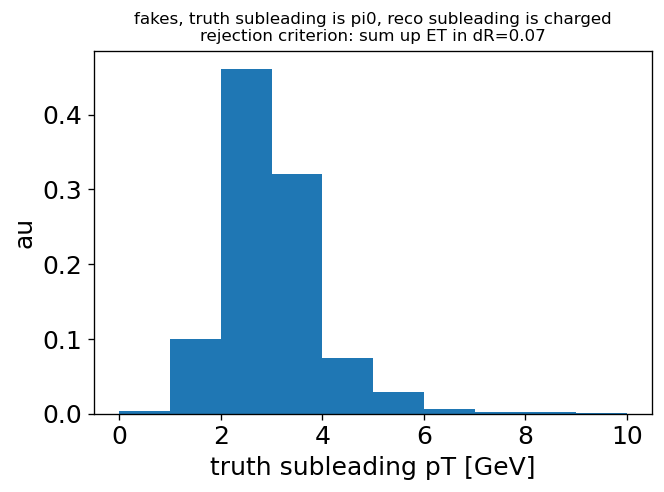

In [82]:
plt.hist(df_fake_sublead111['pt2'], weights=df_fake_sublead111['w'], range=(0,10), density=True)
plt.title('fakes, truth subleading is pi0, reco subleading is charged\nrejection criterion: sum up ET in dR=0.07', fontsize=10)
plt.xlabel('truth subleading pT [GeV]')
plt.ylabel('au')

Text(0, 0.5, 'truth subleading pT [GeV]')

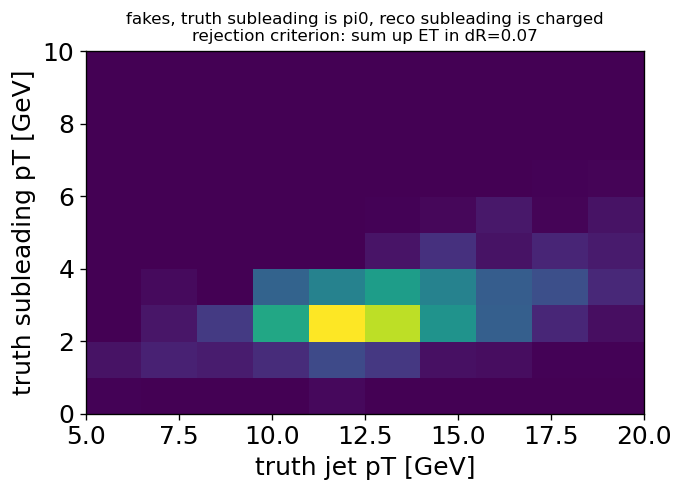

In [90]:
plt.hist2d(df_fake_sublead111['pt'], df_fake_sublead111['pt2'], weights=df_fake_sublead111['w'], range=((5,20),(0,10)), density=True)
plt.title('fakes, truth subleading is pi0, reco subleading is charged\nrejection criterion: sum up ET in dR=0.07', fontsize=10)
plt.xlabel('truth jet pT [GeV]')
plt.ylabel('truth subleading pT [GeV]')

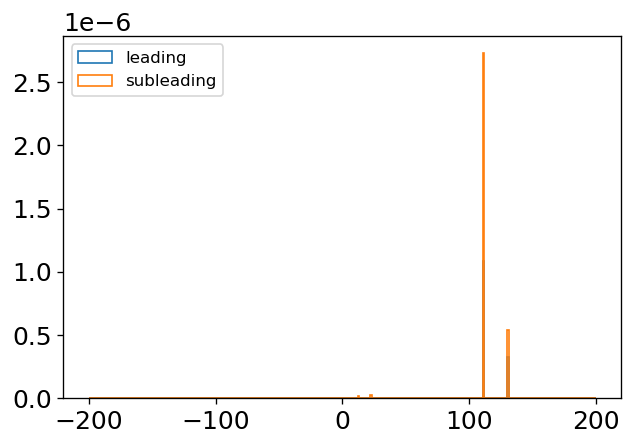

In [78]:
plt.hist(df_fake['pid1'], weights=df_fake['w'], histtype='step', range=(-200,200), bins=400, label='leading')
plt.hist(df_fake['pid2'], weights=df_fake['w'], histtype='step', range=(-200,200), bins=400, label='subleading')
plt.legend(fontsize=10, loc='upper left')

In [53]:
np.unique(df_fake['pid1'])

array([-3322, -3312, -3222, -3212, -3122, -3112, -2212, -2112,  -321,
        -211,    12,    22,   111,   130,   211,   221,   310,   321,
        2112,  2212,  3112,  3122,  3212,  3222,  3312,  3322,  3334],
      dtype=int32)

In [63]:
df[df.bs==0].shape[0]

38490

In [64]:
h,x,y = np.histogram2d(df['bs'],df['b'], bins=([-1.5,-0.5,0.5,1.5]), weights=df['w'], density=True)

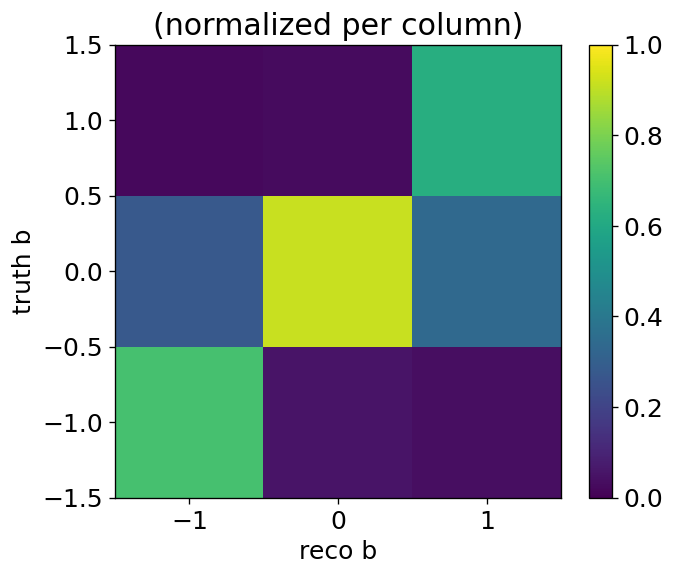

In [65]:
plt.figure(figsize=(6,5))
w = w_norm_per_xbin(h,[-1.5,-0.5,0.5,1.5],[-1.5,-0.5,0.5,1.5])
plt.pcolormesh([-1.5,-0.5,0.5,1.5],[-1.5,-0.5,0.5,1.5], np.transpose(w))
plt.xlabel('reco b')
plt.ylabel('truth b')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(-1.5,1.5)
plt.ylim(-1.5,1.5)
plt.clim(0,1)

In [66]:
w

array([[0.70626165, 0.27407939, 0.01965896],
       [0.05271691, 0.91796342, 0.02931967],
       [0.03878993, 0.33615103, 0.62505904]])

In [41]:
h,x,y = np.histogram2d(df['b'],df['bs'], bins=([-1.5,-0.5,0.5,1.5]), weights=df['w'], density=True)

(-1.5, 1.5)

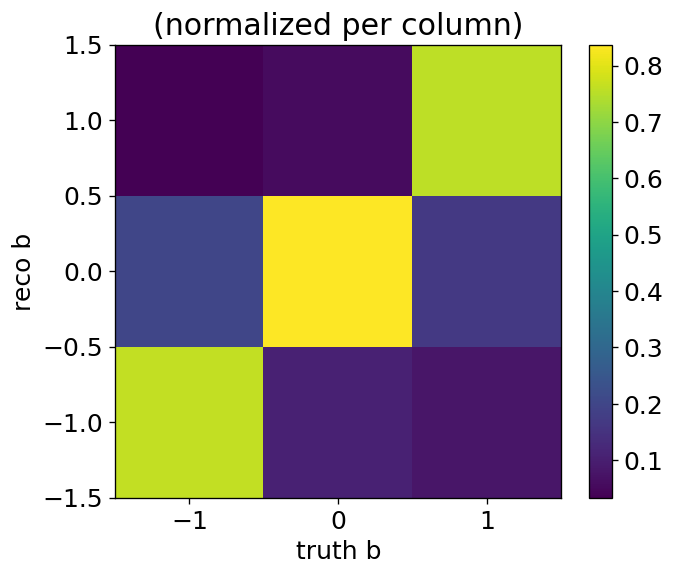

In [42]:
plt.figure(figsize=(6,5))
w = w_norm_per_xbin(h,[-1.5,-0.5,0.5,1.5],[-1.5,-0.5,0.5,1.5])
plt.pcolormesh([-1.5,-0.5,0.5,1.5],[-1.5,-0.5,0.5,1.5], np.transpose(w))
plt.ylabel('reco b')
plt.xlabel('truth b')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(-1.5,1.5)
plt.ylim(-1.5,1.5)

In [13]:
df = applyCut(getData(observables1+observabless1, observables1+observabless1, '$HOME/output/run12/all_pid_new.root', "MatchedTree"),'bs!=0 and bs!=-9 and b!=0 and b!=-9 and reject<=0 and rejects<=0 and 10<pts<30')

In [14]:
rcs_0 = getRcs(applyCut(df,'10<pts<15'))
rcs_err_0 = getRcsErr(applyCut(df,'10<pts<15'))

In [15]:
rcs_1 = getRcs(applyCut(df,'15<pts<20'))
rcs_err_1 = getRcsErr(applyCut(df,'15<pts<20'))

In [16]:
rcs_2 = getRcs(applyCut(df,'20<pts<30'))
rcs_err_2 = getRcsErr(applyCut(df,'20<pts<30'))

In [17]:
rc_0 = getRc(applyCut(df,'10<pts<15'))
rc_err_0 = getRcErr(applyCut(df,'10<pts<15'))

In [18]:
rc_1 = getRc(applyCut(df,'15<pts<20'))
rc_err_1 = getRcErr(applyCut(df,'15<pts<20'))

In [19]:
rc_2 = getRc(applyCut(df,'20<pts<30'))
rc_err_2 = getRcErr(applyCut(df,'20<pts<30'))

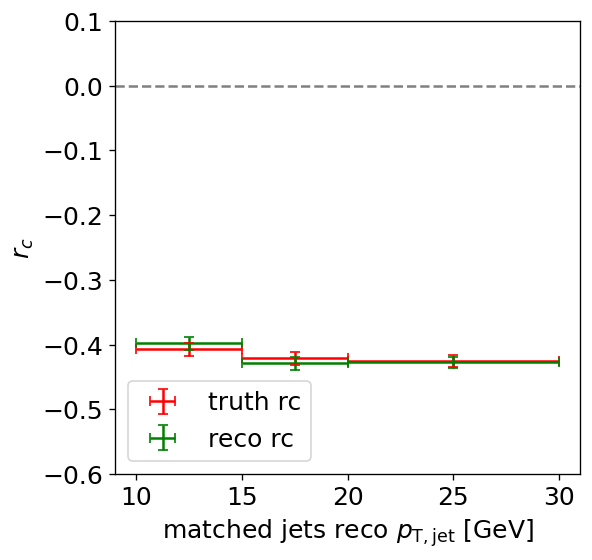

In [20]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([12.5, 17.5, 25], [rc_0, rc_1, rc_2], xerr=[2.5, 2.5, 5], yerr=[rc_err_0, rc_err_1, rc_err_2], capsize=3, color='r', ls='none', label='truth rc')
plt.errorbar([12.5, 17.5, 25], [rcs_0, rcs_1, rcs_2], xerr=[2.5, 2.5, 5], yerr=[rcs_err_0, rcs_err_1, rcs_err_2], capsize=3, color='g', ls='none', label='reco rc')
plt.xlabel('matched jets reco $p_{\mathrm{T, jet}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$r_c$')
plt.ylim(-0.6,0.1)
plt.legend()

In [21]:
df = applyCut(getData(observables1+observabless1, observables1+observabless1, '$HOME/output/run12/all_pid_new.root', "MatchedTree"),'bs!=0 and bs!=-9 and b!=0 and b!=-9 and reject<=0 and rejects<=0 and 10<pt<30')

In [22]:
rcs_0 = getRcs(applyCut(df,'10<pt<15'))
rcs_err_0 = getRcsErr(applyCut(df,'10<pt<15'))

In [23]:
rcs_1 = getRcs(applyCut(df,'15<pt<20'))
rcs_err_1 = getRcsErr(applyCut(df,'15<pt<20'))

In [24]:
rcs_2 = getRcs(applyCut(df,'20<pt<30'))
rcs_err_2 = getRcsErr(applyCut(df,'20<pt<30'))

In [25]:
rc_0 = getRc(applyCut(df,'10<pt<15'))
rc_err_0 = getRcErr(applyCut(df,'10<pt<15'))

In [26]:
rc_1 = getRc(applyCut(df,'15<pt<20'))
rc_err_1 = getRcErr(applyCut(df,'15<pt<20'))

In [27]:
rc_2 = getRc(applyCut(df,'20<pt<30'))
rc_err_2 = getRcErr(applyCut(df,'20<pt<30'))

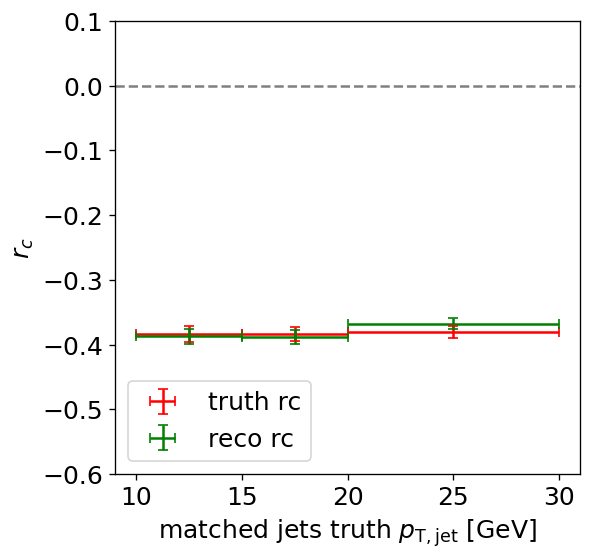

In [28]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([12.5, 17.5, 25], [rc_0, rc_1, rc_2], xerr=[2.5, 2.5, 5], yerr=[rc_err_0, rc_err_1, rc_err_2], capsize=3, color='r', ls='none', label='truth rc')
plt.errorbar([12.5, 17.5, 25], [rcs_0, rcs_1, rcs_2], xerr=[2.5, 2.5, 5], yerr=[rcs_err_0, rcs_err_1, rcs_err_2], capsize=3, color='g', ls='none', label='reco rc')
plt.xlabel('matched jets truth $p_{\mathrm{T, jet}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$r_c$')
plt.ylim(-0.6,0.1)
plt.legend()

In [29]:
df = applyCut(getData(observables1+observabless1, observables1+observabless1, '$HOME/output/run12/all_pid_new.root', "MatchedTree"),'bs!=0 and bs!=-9 and b==bs and reject<=0 and rejects<=0 and 10<pt<30')

In [30]:
rc_0 = getRc(applyCut(df,'10<pt<15'))
rc_err_0 = getRcErr(applyCut(df,'10<pt<15'))

In [31]:
rc_1 = getRc(applyCut(df,'15<pt<20'))
rc_err_1 = getRcErr(applyCut(df,'15<pt<20'))

In [32]:
rc_2 = getRc(applyCut(df,'20<pt<30'))
rc_err_2 = getRcErr(applyCut(df,'20<pt<30'))

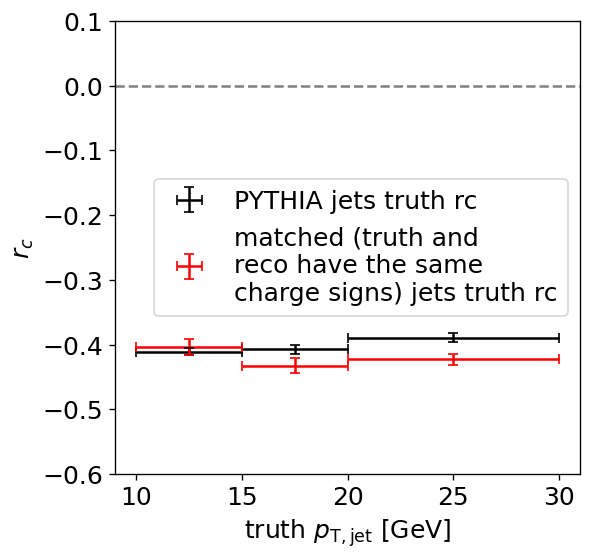

In [33]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([12.5, 17.5, 25], [-0.411037,-0.406995,-0.389326], xerr=[2.5, 2.5, 5], yerr=[0.00528726, 0.0068786, 0.0065369], capsize=3, color='k', ls='none', label='PYTHIA jets truth rc')
plt.errorbar([12.5, 17.5, 25], [rc_0, rc_1, rc_2], xerr=[2.5, 2.5, 5], yerr=[rc_err_0, rc_err_1, rc_err_2], capsize=3, color='r', ls='none', label='matched (truth and \nreco have the same\ncharge signs) jets truth rc')
plt.xlabel('truth $p_{\mathrm{T, jet}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$r_c$')
plt.ylim(-0.6,0.1)
plt.legend()

In [34]:
df = applyCut(getData(observables1+observabless1, observables1+observabless1, '$HOME/output/run12/all_pid_new.root', "MatchedTree"),'bs!=0 and bs!=-9 and b==bs and reject<=0 and rejects<=0 and 10<pts<30')

In [35]:
rcs_0 = getRcs(applyCut(df,'10<pts<15'))
rcs_err_0 = getRcsErr(applyCut(df,'10<pts<15'))

In [36]:
rcs_1 = getRcs(applyCut(df,'15<pts<20'))
rcs_err_1 = getRcsErr(applyCut(df,'15<pts<20'))

In [37]:
rcs_2 = getRcs(applyCut(df,'20<pts<30'))
rcs_err_2 = getRcsErr(applyCut(df,'20<pts<30'))

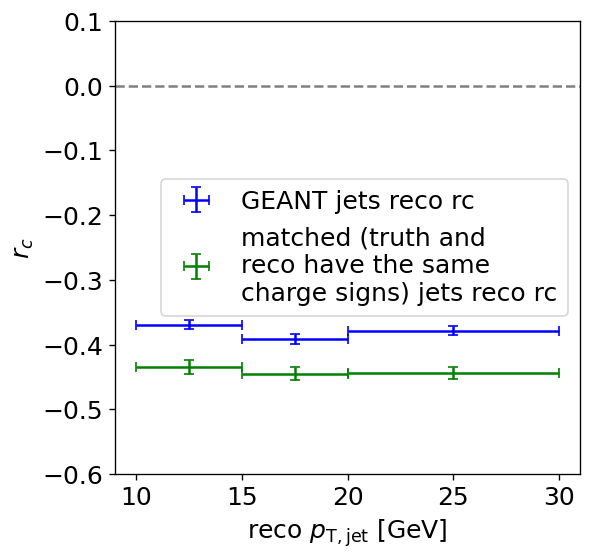

In [38]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([12.5, 17.5, 25], [-0.3692052788091335,-0.39125448790132333,-0.37896559276422115], xerr=[2.5, 2.5, 5], yerr=[0.006897886850187349,0.007238693512313462,0.006992252096104474], capsize=3, color='b', ls='none', label='GEANT jets reco rc')
plt.errorbar([12.5, 17.5, 25], [rcs_0, rcs_1, rcs_2], xerr=[2.5, 2.5, 5], yerr=[rcs_err_0, rcs_err_1, rcs_err_2], capsize=3, color='g', ls='none', label='matched (truth and \nreco have the same\ncharge signs) jets reco rc')
plt.xlabel('reco $p_{\mathrm{T, jet}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$r_c$')
plt.ylim(-0.6,0.1)
plt.legend()